## Kalman filter for options

In [1]:
%load_ext autoreload
%autoreload 1

%aimport openqai.core
%aimport openqai.data.massive.client
%aimport openqai.data.massive.processing
%aimport openqai.data.massive.options.contracts
%aimport openqai.benchmarks.ncde.implied.day

In [2]:



from datetime import date
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
from cdxcore.subdir import SubDir
from cdxcore.util import fmt_list
from cdxcore.uniquehash import named_unique_filename48_8
import polars as pl

from openqai.core.biz_calendar import prev_business_day
from openqai.data.massive.client import MassiveClient
from openqai.core.pool import PoolConfig
from openqai.data.massive.options.contracts import ContractsFilter, filter_contracts, REJECTED
from openqai.data.massive.processing import TradeQuoteAlignmentConfig, align_trades_to_quotes, align_quotes_to_trades, filter_valid_quotes, filter_valid_trades

from cdxcore.version import version
from cdxcore.verbose import Context
from dataclasses import asdict, dataclass, field
from cdxcore.uniquehash import unique_hash8 
import numpy as np
import math
import warnings

from IPython.display import display, Markdown, clear_output

from openqai.benchmarks.ncde.implied.day import OptionQuotesDayConfig, generate_day

option_quotes_day_config = OptionQuotesDayConfig()
ticker     = "SPY"
d          = prev_business_day(date(2025,1,23), exclude_half_days=True, count_start=True )
pool_config= PoolConfig(num_workers=4, threading=False) 
results    = generate_day( ticker, d, option_quotes_day_config=option_quotes_day_config, pool_config=pool_config, verbose=Context.all )

for expiry, df_dict in results.items():
    display(Markdown(f"## Expiry {expiry}"))
    display(df_dict)


00: SPY 2025-01-23: Starting data generation with config mxn=1000,max_dte=7,max_mns=2,min_opt_vol_k=0,bck=250,fwd=250):
00: SPY 2025-01-23: Limiting to at most 1000 options per expiry, selected by smallest absolute nms5:
01:   SPY 2025-01-23 expiry 2025-01-23: Selected 32/32 options, sorted by smallest absolute nms5. Resulting options range from nms5 -0.848 to 0.851.
01:   SPY 2025-01-23 expiry 2025-01-24: Selected 52/52 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.104 to 1.097.
01:   SPY 2025-01-23 expiry 2025-01-27: Selected 50/50 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.233 to 1.219.
01:   SPY 2025-01-23 expiry 2025-01-28: Selected 54/54 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.351 to 1.330.
01:   SPY 2025-01-23 expiry 2025-01-29: Selected 59/59 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.372 to 1.433.
01:   SPY 2025-01-23 expiry 2025-0

## Expiry 2025-01-23

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,trade_dte,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol,paired_opt_ticker
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
0.000082,3.0,0.998928,3.0,3.5564e-7,3.4188e-7,2.9299e-7,2.7466e-7,0.000091,0.000008,0.998928,0.000016,217.0,0.479263,1000.0,0.3,-1.0,0.0,-1.4943e-16,0.0,0.0,0.0,0.8,3.5556e-8,0.0,0.8,0.0,0.0,0.483692,2025-01-23,2025-01-23,1.00587,"""SPY""","""O:SPY250123C00610000""",true,true,606.44,0.000016,0.0,false,0.047915,24.001386,0.005617,0.065208,0.073713,0.054553,25.604769,0.006228,0.075145,0.076613,0.051161,24.810124,0.005918,0.070041,0.075141,"""O:SPY250123P00610000"""
0.000824,10.0,0.998945,10.0,0.000002,0.00001,0.000001,0.000001,0.000833,0.000025,0.998928,0.000016,88.0,0.5,600.0,0.166667,-0.333333,1.0,0.0,0.0,0.000017,0.0,0.799999,9.9017e-7,0.0,0.799992,0.000001,0.000001,0.139362,2025-01-23,2025-01-23,1.000923,"""SPY""","""O:SPY250123C00607000""",true,true,606.44,0.000016,0.0,false,0.311457,87.473986,0.019918,0.225016,0.071727,0.317324,85.236408,0.020078,0.234643,0.0742,0.31444,86.342081,0.02,0.229845,0.072966,"""O:SPY250123P00607000"""
0.000824,10.0,0.998928,100.0,0.000003,0.00001,0.000003,0.000003,0.000841,0.000016,0.99892,0.000025,88.0,0.5,600.0,0.166667,-1.0,0.333333,0.009901,0.0,-0.000017,-0.000008,0.799998,0.000001,0.0,0.799992,0.000001,0.000001,0.139938,2025-01-23,2025-01-23,1.000923,"""SPY""","""O:SPY250123C00607000""",true,true,606.44,0.000016,0.0,false,0.313051,86.514156,0.019962,0.228518,0.072683,0.31692,85.041465,0.020067,0.234928,0.07433,0.315007,85.77208,0.020016,0.23173,0.073508,"""O:SPY250123P00607000"""
0.000824,10.0,0.998928,100.0,0.000003,0.00001,0.000003,0.000003,0.000833,0.000025,0.99892,0.000025,88.0,0.5,600.0,0.166667,-0.333333,0.333333,-0.009804,0.0,0.0,0.0,0.799997,2.3923e-7,0.0,0.799992,0.0,0.0,0.139938,2025-01-23,2025-01-23,1.000923,"""SPY""","""O:SPY250123C00607000""",true,true,606.44,0.000016,0.0,false,0.31105,87.26788,0.019907,0.225292,0.071856,0.31692,85.041465,0.020067,0.234928,0.07433,0.314035,86.141674,0.019989,0.230126,0.073096,"""O:SPY250123P00607000"""
0.000049,1.0,0.998928,100.0,0.000004,0.00001,0.000003,0.000003,0.000041,0.000008,0.99892,0.000025,1266.0,0.492891,600.0,0.166667,1.0,0.333333,0.0,0.0,-0.000017,0.000008,0.799997,0.000004,0.0,0.799992,0.000003,0.000003,0.598669,2025-01-23,2025-01-23,1.007519,"""SPY""","""O:SPY250123C00611000""",true,true,606.44,0.000016,0.0,false,0.021194,12.054662,0.002865,0.033793,0.074877,0.029001,14.647988,0.003727,0.047059,0.080158,0.025016,13.383836,0.003295,0.040241,0.077546,"""O:SPY250123P00611000"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,1.0,null,0.999999,0.999999,0.012862,0.001501,1.005409,0.000016,105.0,0.009524,16600.0,0.981928,null,-1.0,0.0,null,0.0,-0.000008,2.6701e-7,0.000003,null,null,0.000004,0.000004,-0.958502,2025-01-23,2025-01-23,0.992679,"""SPY""","""O:SPY250123C00602000""",true,true,606.44,0.000016,0.01273,true,1.0,0.0,0.0,0.0,0.01,1.0,0.0,0.0,0.0,5.0,1.0,0.0,0.0,0.0,5.0,"""O:SPY250123P00602000"""
null,null,1.005392,100.0,1.0,null,0.999999,0.999999,0.007404,0.001352,1.005409,0.000016,96.0,0.010417,16600.0,0.981928,null,-1.0,-0.07518,null,0.0,-0.000008,2.5846e-7,0.000003,null,null,0.000004,0.000004,-0.584575,202

## Expiry 2025-01-24

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,trade_dte,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol,paired_opt_ticker
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
0.00028,2.0,0.998945,100.0,2.5953e-7,4.2735e-7,9.2009e-8,8.3846e-8,0.000264,0.000016,0.998912,0.000033,214.0,0.5,2200.0,0.272727,1.0,1.0,0.032258,0.0,0.0,0.0,1.8,5.7393e-8,0.0,1.8,0.0,0.0,-1.049848,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124P00596000""",true,false,606.44,0.000016,0.0,false,-0.056327,11.012332,0.00958,0.081676,0.121793,-0.061146,11.438605,0.010218,0.089448,0.125058,-0.05874,11.230571,0.009902,0.085553,0.123433,"""O:SPY250124C00596000"""
null,null,0.998928,3.0,3.2855e-7,null,2.9299e-7,2.7466e-7,0.000074,0.000008,0.998928,0.000016,238.0,0.5,1000.0,0.3,null,0.0,1.8264e-16,null,0.000033,0.000008,1.8,5.1624e-8,null,null,3.1581e-8,8.0940e-8,0.868295,2025-01-24,2025-01-23,1.012466,"""SPY""","""O:SPY250124C00614000""",true,true,606.44,0.000016,0.0,false,0.025391,8.606818,0.005004,0.028514,0.0814,0.029911,9.507781,0.005736,0.033918,0.084468,0.027692,9.076894,0.00538,0.031255,0.082986,"""O:SPY250124P00614000"""
0.000198,1.0,0.998928,3.0,3.3560e-7,2.9915e-7,2.9299e-7,2.7466e-7,0.000214,0.000016,0.998928,0.000016,200.0,0.5,1000.0,0.3,-1.0,0.0,-0.071429,0.0,0.000033,0.000008,1.8,5.8034e-8,0.0,1.8,3.1581e-8,8.0940e-8,0.657848,2025-01-24,2025-01-23,1.009168,"""SPY""","""O:SPY250124C00612000""",true,true,606.44,0.000016,0.0,false,0.066819,19.093304,0.010948,0.061517,0.080273,0.073791,19.899507,0.011816,0.068759,0.08313,0.070315,19.510613,0.011387,0.065129,0.081708,"""O:SPY250124P00612000"""
null,null,0.998928,3.0,4.1380e-7,null,2.9299e-7,2.7466e-7,0.000132,0.000016,0.998928,0.000016,226.0,0.5,1000.0,0.3,null,0.0,0.0,null,0.000033,0.000008,1.8,1.3432e-7,null,null,3.1581e-8,8.0940e-8,0.763158,2025-01-24,2025-01-23,1.010817,"""SPY""","""O:SPY250124C00613000""",true,true,606.44,0.000016,0.0,false,0.041785,13.082875,0.007546,0.042649,0.080746,0.049739,14.33163,0.00868,0.051523,0.084794,0.045853,13.744916,0.008133,0.047159,0.082837,"""O:SPY250124P00613000"""
null,null,0.998928,3.0,4.1615e-7,null,2.9299e-7,2.7466e-7,0.000346,0.000016,0.998928,0.000016,176.0,0.5,1000.0,0.3,null,0.0,-0.023256,null,0.000033,0.000008,1.8,1.3496e-7,null,null,3.1581e-8,8.0940e-8,0.552367,2025-01-24,2025-01-23,1.007519,"""SPY""","""O:SPY250124C00611000""",true,true,606.44,0.000016,0.0,false,0.102997,26.55158,0.015155,0.084769,0.079908,0.109099,26.953646,0.015798,0.090747,0.082058,0.106087,26.762579,0.015483,0.087781,0.080994,"""O:SPY250124P00611000"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.022855,0.000198,1.005409,0.000016,35.0,0.714286,16600.0,0.981928,null,-1.0,0.000722,null,-0.000033,-0.000025,1.000001,0.000004,null,null,0.000005,0.000005,-1.562817,2025-01-24,2025-01-23,0.982785,"""SPY""","""O:SPY250124C00596000""",true,true,606.44,0.000016,0.022624,false,0.968023,5.819222,0.004519,0.11141,0.195679,0.923835,8.957452,0.009023,0.288564,0.253831,0.943088,7.903624,0.007199,0.208208,0.229536,"""O:SPY250124P00596000"""
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.004914,0.000082,1.005409,0.000016,211.0,0.49763,16600.0,0.981928,null,-1.0,0.003367,null,0.0,-0.000008,1.000

## Expiry 2025-01-27

... (7 outputs left out)

## Expiry 2025-01-31

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,trade_dte,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol,paired_opt_ticker
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
0.006876,3.0,0.998928,3.0,4.8927e-7,2.1368e-7,2.9299e-7,2.7466e-7,0.006851,0.000091,0.998928,0.000016,20.0,0.5,1000.0,0.3,0.272727,0.0,-0.002401,0.0,-0.000017,0.000017,6.8,2.5658e-7,0.0,6.8,2.0098e-7,1.9081e-7,0.097705,2025-01-31,2025-01-23,1.000923,"""SPY""","""O:SPY250131C00607000""",true,true,606.44,0.000016,0.0,false,0.462722,20.550912,0.065247,0.142248,0.117658,0.46376,20.08146,0.065263,0.145644,0.120438,0.463247,20.313475,0.065255,0.143946,0.119048,"""O:SPY250131P00607000"""
0.00526,122.0,0.998928,3.0,4.8927e-7,2.1368e-7,2.9299e-7,2.7466e-7,0.005227,0.000082,0.998928,0.000016,20.0,0.5,1000.0,0.3,0.4,0.0,-0.001575,0.0,-0.000017,0.000017,6.8,2.6491e-7,0.0,6.8,2.0098e-7,1.9081e-7,0.258774,2025-01-31,2025-01-23,1.004221,"""SPY""","""O:SPY250131C00609000""",true,true,606.44,0.000016,0.0,false,0.392599,20.505739,0.063144,0.13352,0.114117,0.395106,20.082594,0.063255,0.136812,0.116726,0.393867,20.291977,0.063201,0.135167,0.115422,"""O:SPY250131P00609000"""
null,null,0.998945,100.0,8.4376e-7,null,8.2812e-7,7.8145e-7,0.00451,0.000025,0.998928,0.000016,88.0,0.5,600.0,0.166667,null,1.0,0.001832,null,0.000017,0.0,6.799999,3.5299e-7,null,null,5.3513e-7,5.0679e-7,0.339111,2025-01-31,2025-01-23,1.00587,"""SPY""","""O:SPY250131C00610000""",true,true,606.44,0.000016,0.0,false,0.358363,20.07132,0.061359,0.128804,0.11329,0.35937,19.948984,0.061419,0.129847,0.114096,0.358869,20.00997,0.061389,0.129326,0.113693,"""O:SPY250131P00610000"""
0.006876,3.0,0.998945,100.0,8.6329e-7,2.1368e-7,8.2812e-7,7.8145e-7,0.006818,0.000124,0.998928,0.000016,20.0,0.5,600.0,0.166667,0.466667,1.0,-0.004813,0.0,0.000017,0.0,6.799999,3.7402e-7,0.0,6.8,5.3513e-7,5.0679e-7,0.097705,2025-01-31,2025-01-23,1.000923,"""SPY""","""O:SPY250131C00607000""",true,true,606.44,0.000016,0.0,false,0.462334,20.72711,0.065241,0.141013,0.116648,0.46376,20.08146,0.065263,0.145644,0.120438,0.463057,20.399178,0.065252,0.143329,0.118543,"""O:SPY250131P00607000"""
0.00526,122.0,0.998945,100.0,8.6389e-7,2.1368e-7,8.2812e-7,7.8145e-7,0.005202,0.000107,0.998928,0.000016,20.0,0.5,600.0,0.166667,0.538462,1.0,-0.004732,0.0,0.000017,0.0,6.799999,3.7462e-7,0.0,6.8,5.3513e-7,5.0679e-7,0.258774,2025-01-31,2025-01-23,1.004221,"""SPY""","""O:SPY250131C00609000""",true,true,606.44,0.000016,0.0,false,0.391826,20.636156,0.063109,0.13253,0.113333,0.395106,20.082594,0.063255,0.136812,0.116726,0.393489,20.35564,0.063184,0.134673,0.115031,"""O:SPY250131P00609000"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.016094,0.000132,1.005409,0.000016,60.0,0.833333,16600.0,0.981928,null,-1.0,0.002053,null,0.0,-0.000008,6.000001,0.000002,null,null,0.000004,0.000004,0.766063,2025-01-31,2025-01-23,1.020711,"""SPY""","""O:SPY250131P00619000""",true,false,606.44,0.000016,0.015302,false,-0.88083,15.623069,0.030716,0.053264,0.082575,-0.858375,16.039352,0.034614,0.065886,0.09064,-0.869083,15.884795,0.032801,0.05974,0.086727,"""O:SPY250131C00619000"""
null,null,1.005392,100.0,1.0,null,0.999999,0.999999,0.000907,0.000016,1.005409,0.000016,478.0,0.617155,16600.0,0.981

## Expiry 2025-02-03

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,trade_dte,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol,paired_opt_ticker
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
null,null,0.998928,3.0,4.1923e-7,null,2.9299e-7,2.7466e-7,0.000841,0.000016,0.998928,0.000016,103.0,0.145631,1000.0,0.3,null,0.0,0.02,null,-0.000017,0.000017,7.8,2.1120e-7,null,null,2.0098e-7,1.9081e-7,1.090058,2025-02-03,2025-01-23,1.02236,"""SPY""","""O:SPY250203C00620000""",true,true,606.44,0.000016,0.0,false,0.098559,9.726506,0.03055,0.050078,0.101476,0.10095,9.795008,0.03109,0.0515,0.102546,0.099761,9.761385,0.030822,0.050792,0.102013,"""O:SPY250203P00620000"""
null,null,0.998928,3.0,4.5115e-7,null,2.9299e-7,2.7466e-7,0.000849,0.000025,0.998928,0.000016,43.0,0.348837,1000.0,0.3,null,0.0,0.009804,null,0.0,0.0,7.8,3.1923e-8,null,null,0.0,0.0,1.090058,2025-02-03,2025-01-23,1.02236,"""SPY""","""O:SPY250203C00620000""",true,true,606.44,0.000016,0.0,false,0.098559,9.726506,0.03055,0.050078,0.101476,0.102127,9.827423,0.031353,0.052204,0.103074,0.100357,9.77835,0.030956,0.051147,0.10228,"""O:SPY250203P00620000"""
null,null,0.998928,3.0,7.5744e-7,null,2.9299e-7,2.7466e-7,0.00122,0.000033,0.998928,0.000016,54.0,0.5,1000.0,0.3,null,0.0,0.006803,null,0.0,0.0,7.799999,2.6795e-7,null,null,0.0,0.0,-1.481327,2025-02-03,2025-01-23,0.967944,"""SPY""","""O:SPY250203P00587000""",true,false,606.44,0.000016,0.0,false,-0.099982,7.068572,0.030872,0.070368,0.141103,-0.103272,7.130478,0.031608,0.073125,0.143215,-0.101639,7.100376,0.031244,0.071753,0.142165,"""O:SPY250203C00587000"""
null,null,0.998895,100.0,0.000002,null,0.000002,0.000001,0.002844,0.000025,0.99892,0.000025,112.0,0.5,600.0,0.166667,null,-1.0,0.0,null,-0.00005,-0.000008,7.799998,0.000001,null,null,9.3739e-7,7.0893e-7,-0.765589,2025-02-03,2025-01-23,0.982785,"""SPY""","""O:SPY250203P00596000""",true,false,606.44,0.000016,0.0,false,-0.223212,13.760282,0.052526,0.104641,0.123325,-0.224885,13.714313,0.052749,0.105886,0.124265,-0.224052,13.737321,0.052638,0.105265,0.123796,"""O:SPY250203C00596000"""
null,null,0.998895,100.0,0.000002,null,0.000002,0.000001,0.007503,0.000033,0.99892,0.000025,78.0,0.5,600.0,0.166667,null,-1.0,-0.002193,null,-0.00005,0.0,7.799998,7.5201e-7,null,null,6.0248e-7,4.5641e-7,0.094199,2025-02-03,2025-01-23,1.000923,"""SPY""","""O:SPY250203C00607000""",true,true,606.44,0.000016,0.0,false,0.466408,18.821072,0.069938,0.135633,0.120054,0.466735,18.675672,0.069943,0.136708,0.120997,0.466572,18.74809,0.069941,0.13617,0.120525,"""O:SPY250203P00607000"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,0.999999,null,0.999995,0.999995,0.026919,0.000124,1.005417,0.000025,66.0,0.5,1800.0,0.888889,null,-1.0,0.0,null,0.0,0.0,7.000001,0.000001,null,null,0.0,0.0,-1.187013,2025-02-03,2025-01-23,0.981136,"""SPY""","""O:SPY250203C00595000""",true,true,606.44,0.000016,0.024281,false,0.821149,9.688392,0.043558,0.126897,0.161851,0.813242,9.620669,0.04475,0.134882,0.167452,0.817127,9.656172,0.044169,0.13092,0.16467,"""O:SPY250203P00595000"""
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.02546,0.000132,1.005409,0.000016,66.0,0.5,16600.0,0.981928,null,-1.0,0.0,null,-0.000033,0.000008,7.000001,0.000007,null,null,0.000008,0.000008,-1.105078,2025-02-03,2025

## Expiry 2025-01-23 for SPY 2025-01-23

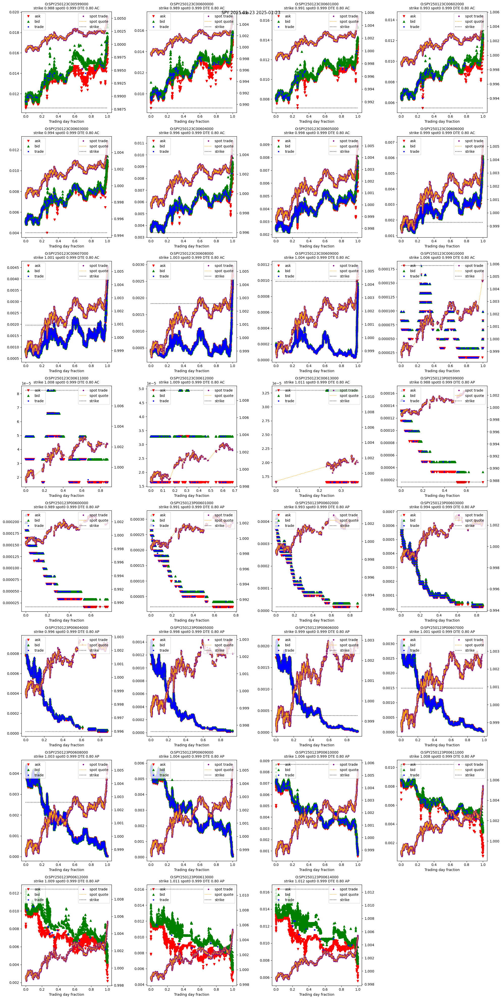

## Expiry 2025-01-24 for SPY 2025-01-23

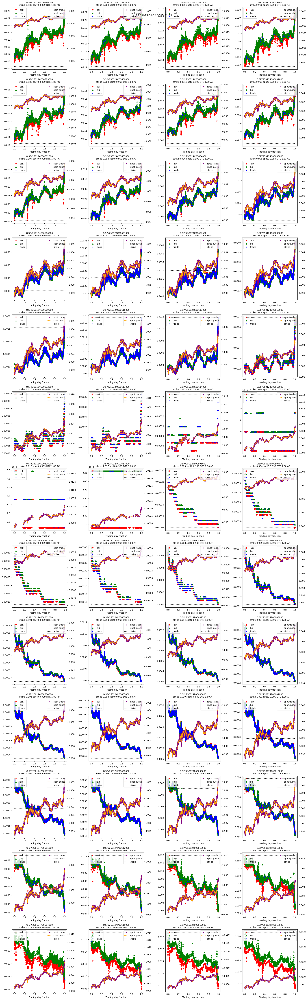

## Expiry 2025-01-27 for SPY 2025-01-23

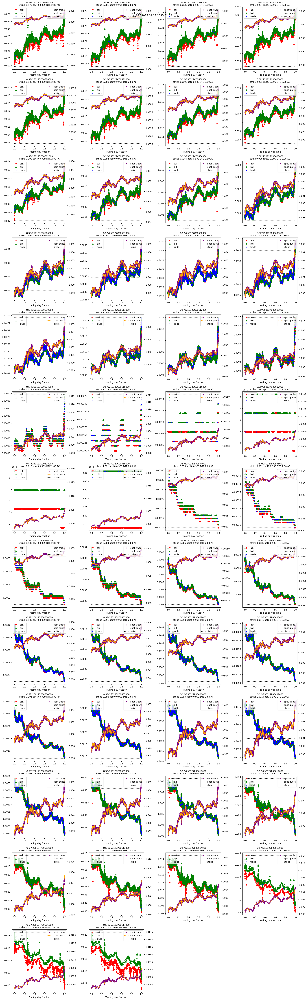

## Expiry 2025-01-28 for SPY 2025-01-23

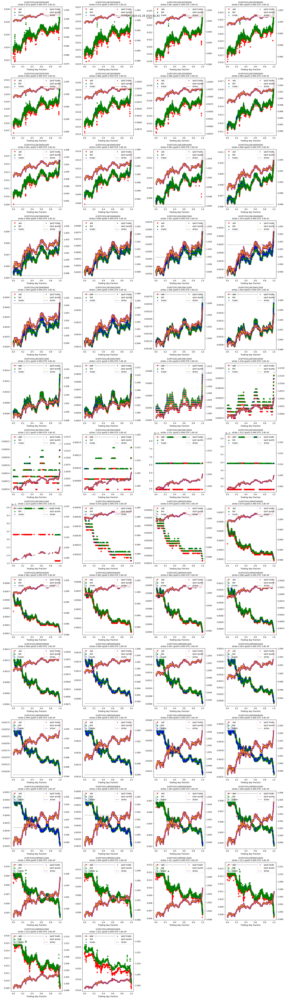

## Expiry 2025-01-29 for SPY 2025-01-23

In [ ]:
from cdxcore.dynaplot import figure, colors_tableau

def plot_expiry( ticker, d, expiry, slc = slice(None) ):
    display(Markdown(f"## Expiry {expiry} for {ticker} {d}"))

    opt_tickers = sorted( df_dict["opt_ticker"].unique().to_list() )
    date = df_dict["date"].unique()[0] if "date" in df_dict.columns else d

    with figure(f"SPY {expiry} {date}", row_size=5, col_size=5, columns=4) as fig:

        for opt_ticker in opt_tickers:
            df_opt = df_dict.filter(pl.col("opt_ticker") == opt_ticker)

            spot_mid_price   = df_opt["spot_mid_price"].to_numpy()[slc]
            spot_trade_price = df_opt["spot_trade_price"].to_numpy()[slc]
            opt_mid_price    = df_opt["mid_price"].to_numpy()[slc]
            opt_half_spread  = df_opt["half_spread"].to_numpy()[slc]
            opt_trade_price  = df_opt["trade_price"].to_numpy()[slc]
 
            spot_quote_t_d   = df_opt["spot_quote_t_d"].to_numpy()[slc]
            spot_trade_t_d   = df_opt["spot_trade_t_d"].to_numpy()[slc]  
            opt_quote_t_d    = df_opt["t_d"].to_numpy()[slc]
            opt_trade_t_d    = df_opt["trade_t_d"].to_numpy()[slc]

            is_valid_spot_quote = np.isfinite(spot_mid_price)
            is_valid_spot_trade = np.isfinite(spot_trade_price)
            is_valid_opt_quote  = np.isfinite(opt_mid_price)
            is_valid_opt_trade  = np.isfinite(opt_trade_price)

            assert np.all( np.isfinite(spot_quote_t_d) == is_valid_spot_quote ), f"{opt_ticker} spot quote t_d should be finite if and only if spot mid price is finite"
            assert np.all( np.isfinite(spot_trade_t_d) == is_valid_spot_trade ), f"{opt_ticker} spot trade t_d should be finite if and only if spot trade price is finite"
            assert np.all( np.isfinite(opt_quote_t_d) == is_valid_opt_quote ), f"{opt_ticker} opt quote t_d should be finite if and only if opt mid price is finite"
            assert np.all( np.isfinite(opt_trade_t_d) == is_valid_opt_trade ), f"{opt_ticker} opt trade t_d should be finite if and only if opt trade price is finite"

            spot_quote_t_d   = spot_quote_t_d[is_valid_spot_quote]
            spot_trade_t_d   = spot_trade_t_d[is_valid_spot_trade]
            opt_quote_t_d    = opt_quote_t_d[is_valid_opt_quote]
            opt_trade_t_d    = opt_trade_t_d[is_valid_opt_trade]

            spot_mid_price   = spot_mid_price[is_valid_spot_quote]
            spot_trade_price = spot_trade_price[is_valid_spot_trade]
            opt_mid_price    = opt_mid_price[is_valid_opt_quote]
            opt_half_spread  = opt_half_spread[is_valid_opt_quote]
            opt_trade_price  = opt_trade_price[is_valid_opt_trade]

            strike           = df_opt["strike"].unique()[0]
            is_call          = df_opt["is_call"].unique()[0]
            is_american      = df_opt["is_american"].unique()[0]
            dte_0            = df_opt["dte"].to_numpy()[is_valid_opt_quote][0]

            opt_ask_price    = opt_mid_price - opt_half_spread  
            opt_bid_price    = opt_mid_price + opt_half_spread

            ax = fig.add_subplot()
            ax.set_title(f"{opt_ticker}\nstrike {strike:.3f} spot0 {spot_mid_price[0]:.3f} DTE {dte_0:.2f} {'A' if is_american else 'E'}{'C' if is_call else 'P'}", fontsize=10)
            ax2 = ax.twinx()
            ax.plot(opt_quote_t_d, opt_ask_price, "v", color="red", label="ask")
            ax.plot(opt_quote_t_d, opt_bid_price, "^", color="green", label="bid")
            ax.plot(opt_trade_t_d, opt_trade_price, ".", color="blue", label="trade")
            
            ax2.plot(spot_trade_t_d, spot_trade_price, ".", color="purple", label="spot trade")
            ax2.plot(spot_quote_t_d, spot_mid_price, ":", color="orange", label="spot quote")
            ax2.plot(spot_quote_t_d, spot_quote_t_d*0.+strike, ":", color="black", label="strike")

            ax.set_xlabel("Trading day fraction")
            ax.legend(loc="upper left")
            ax2.legend(loc="upper right")

for expiry, df_dict in results.items():
    plot_expiry( ticker, d, expiry )





In [ ]:
from cdxcore.dynaplot import figure, colors_tableau

def test_tanh():
    x = np.linspace(-4,4,100)

    with figure("tanh", row_size=5, col_size=5, columns=4) as fig:
        ax = fig.add_subplot()
        for q in [0.1,0.5,1,2,5]:
            ax.plot(x, np.tanh(q*x), label=f"q={q}")

